# Gerçek Veri: Haftalık Çalışma Süresi ve Final Notu

**Veri:** UCI Student Performance (Cortez & Silva, 2008). Portekiz'deki iki ortaokulda Portekizce (n = 649) ve Matematik (n = 395) derslerinin notları ve öğrenci bilgileri. Notlar 0–20 ölçeğindedir: G1 1. dönem, G3 final notu. Lisans: CC BY 4.0.

**Gruplar:** Haftalık çalışma süresi (`studytime`): 1 = < 2 saat, 2 = 2–5 saat, 3 = 5–10 saat, 4 = > 10 saat.

**Araştırma soruları**
1. Final notu (G3) çalışma süresi gruplarına göre farklılaşıyor mu?
2. En yüksek final notu hangi grupta ve bu üstünlük istatistiksel olarak anlamlı mı?
3. Dönem içindeki gelişim (G3 − G1) gruplara göre farklı mı?
4. En iyi grupta 1. dönem notu ile final notu arasında anlamlı fark var mı?
5. Sonuçlar Matematik dersinde tekrarlanıyor mu?

> **Önemli sınırlılık:** Bu bir **gözlemsel** çalışmadır; öğrenciler gruplara rastgele atanmamıştır ve çalışma süresi öğrencinin kendi beyanıdır. Bulunan farklar **ilişki** gösterir, **neden-sonuç** göstermez. Daha çok çalışan öğrenciler zaten daha motive veya başarılı olabilir.

Analiz akışı ve test seçimi `src/istatistik.py` modülünde tanımlıdır: normallik ve homojenlik sağlanırsa ANOVA + Tukey, yalnız normallik sağlanırsa Welch ANOVA + Games-Howell, normallik sağlanmazsa Kruskal-Wallis + Dunn testi kullanılır.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, str(Path("..") / "src"))
import istatistik as ist

VERI = Path("..") / "data"
SEKIL = Path("..") / "figures"
SEKIL.mkdir(exist_ok=True)

ALPHA = ist.ALPHA
ETIKET = {1: "< 2 sa", 2: "2–5 sa", 3: "5–10 sa", 4: "> 10 sa"}
RENK = {1: "#9ecae1", 2: "#6baed6", 3: "#3182bd", 4: "#08519c"}

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Veriyi tanıma

In [2]:
por = pd.read_csv(VERI / "student-por.csv", sep=";")
mat = pd.read_csv(VERI / "student-mat.csv", sep=";")

for ad, veri in [("Portekizce", por), ("Matematik", mat)]:
    print(f"{ad:10} | {veri.shape[0]} öğrenci, {veri.shape[1]} değişken | "
          f"eksik değer: {veri.isna().sum().sum()} | G3 = 0 olan: {(veri.G3 == 0).sum()}")

por[["studytime", "G1", "G2", "G3"]].describe()

Portekizce | 649 öğrenci, 33 değişken | eksik değer: 0 | G3 = 0 olan: 15
Matematik  | 395 öğrenci, 33 değişken | eksik değer: 0 | G3 = 0 olan: 38


,studytime,G1,G2,G3
count,649.000,649.000,649.000,649.000
mean,1.931,11.399,11.570,11.906
std,0.830,2.745,2.914,3.231
min,1.000,0.000,0.000,0.000
25%,1.000,10.000,10.000,10.000
50%,2.000,11.000,11.000,12.000
75%,2.000,13.000,13.000,14.000
max,4.000,19.000,19.000,19.000


### G3 = 0 sorunu

Final notu 0 olan öğrencilerin 1. dönem notları sıfır değildir. Bu öğrenciler büyük olasılıkla final sınavına **girmemiştir**. Bu durumda 0, gerçek bir başarı ölçümü değil, **eksik veridir**. Bu öğrenciler analize katılırsa dağılım bozulur ve ortalamalar düşer.

**Karar:** Ana analiz yalnızca final sınavına giren öğrencilerle (G3 > 0) yapılır. Tüm öğrencilerle yapılan analiz, **duyarlılık analizi** olarak bölüm 6'da raporlanır.

G3 = 0 olan 15 öğrencinin G1 ortalaması: 7.1 (G1 = 0 olan: 0)


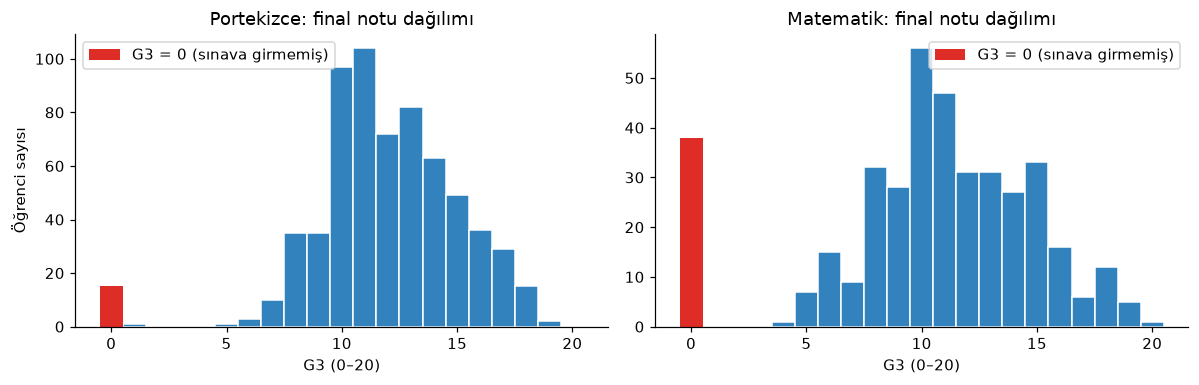

Analize giren: Portekizce 634, Matematik 357 öğrenci


In [3]:
sifirlar = por[por.G3 == 0]
print(f"G3 = 0 olan {len(sifirlar)} öğrencinin G1 ortalaması: {sifirlar.G1.mean():.1f} "
      f"(G1 = 0 olan: {(sifirlar.G1 == 0).sum()})")

fig, eksenler = plt.subplots(1, 2, figsize=(11, 3.6))
for eksen, (ad, veri) in zip(eksenler, [("Portekizce", por), ("Matematik", mat)]):
    eksen.hist(veri.G3, bins=np.arange(-0.5, 21), color="#3182bd", edgecolor="white")
    eksen.bar(0, (veri.G3 == 0).sum(), width=1, color="#de2d26", label="G3 = 0 (sınava girmemiş)")
    eksen.set_title(f"{ad}: final notu dağılımı")
    eksen.set_xlabel("G3 (0–20)")
    eksen.legend()
eksenler[0].set_ylabel("Öğrenci sayısı")
plt.tight_layout()
plt.savefig(SEKIL / "g3_dagilimi.png", bbox_inches="tight")
plt.show()

por_g = por[por.G3 > 0].copy()
mat_g = mat[mat.G3 > 0].copy()
print(f"Analize giren: Portekizce {len(por_g)}, Matematik {len(mat_g)} öğrenci")

## 2. Betimsel istatistikler (Portekizce, G3 > 0)

In [4]:
def betimsel(veri):
    tablo = veri.groupby("studytime").agg(
        n=("G3", "size"), G1_ort=("G1", "mean"), G3_ort=("G3", "mean"), G3_ss=("G3", "std"),
        G3_medyan=("G3", "median"), Gelişim=("G3", lambda s: (s - veri.loc[s.index, "G1"]).mean()))
    tablo.index = [ETIKET[i] for i in tablo.index]
    return tablo

betimsel(por_g)

,n,G1_ort,G3_ort,G3_ss,G3_medyan,Gelişim
< 2 sa,204,10.652,11.270,2.440,11.0,0.618
2–5 sa,298,11.634,12.376,2.690,12.0,0.742
5–10 sa,97,12.423,13.227,2.502,13.0,0.804
> 10 sa,35,12.771,13.057,3.038,13.0,0.286


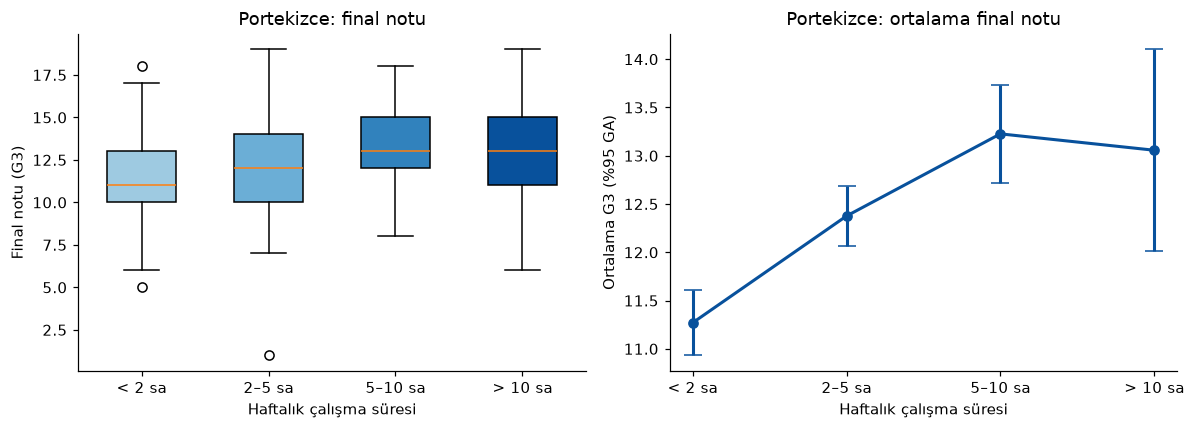

In [5]:
def gruplar(veri, sutun):
    return {ETIKET[k]: v[sutun].to_numpy() for k, v in veri.groupby("studytime")}

fig, eksenler = plt.subplots(1, 2, figsize=(11, 4))
g3 = gruplar(por_g, "G3")
kutu = eksenler[0].boxplot(list(g3.values()), tick_labels=list(g3), patch_artist=True, widths=0.55)
for k, b in zip(ETIKET, kutu["boxes"]):
    b.set_facecolor(RENK[k])
eksenler[0].set_xlabel("Haftalık çalışma süresi")
eksenler[0].set_ylabel("Final notu (G3)")
eksenler[0].set_title("Portekizce: final notu")

ort = por_g.groupby("studytime").G3.agg(["mean", "sem", "size"])
ga = ort["sem"] * stats.t.ppf(0.975, ort["size"] - 1)
eksenler[1].errorbar(range(4), ort["mean"], yerr=ga, fmt="o-", color="#08519c", capsize=6, lw=2)
eksenler[1].set_xticks(range(4), [ETIKET[k] for k in ort.index])
eksenler[1].set_xlabel("Haftalık çalışma süresi")
eksenler[1].set_ylabel("Ortalama G3 (%95 GA)")
eksenler[1].set_title("Portekizce: ortalama final notu")
plt.tight_layout()
plt.savefig(SEKIL / "portekizce_g3_gruplar.png", bbox_inches="tight")
plt.show()

## 3. Soru 1–2: Final notu gruplara göre farklı mı?

**Varsayım kontrolleri:** Normallik için Shapiro-Wilk, varyans homojenliği için Levene testi kullanılır.

In [6]:
s_g3 = ist.grup_karsilastir(g3)
print(f"Levene: {ist.p_yaz(s_g3.levene_p)} | Homojen mi? {ist.evet_hayir(s_g3.levene_p > ALPHA)}\n")
s_g3.normallik

Levene: p = .083 | Homojen mi? Evet



,Grup,n,W,p,Normal mi?
0,< 2 sa,204,0.969,1.639e-04,Hayır
1,2–5 sa,298,0.972,1.525e-05,Hayır
2,5–10 sa,97,0.970,2.494e-02,Hayır
3,> 10 sa,35,0.955,1.659e-01,Evet


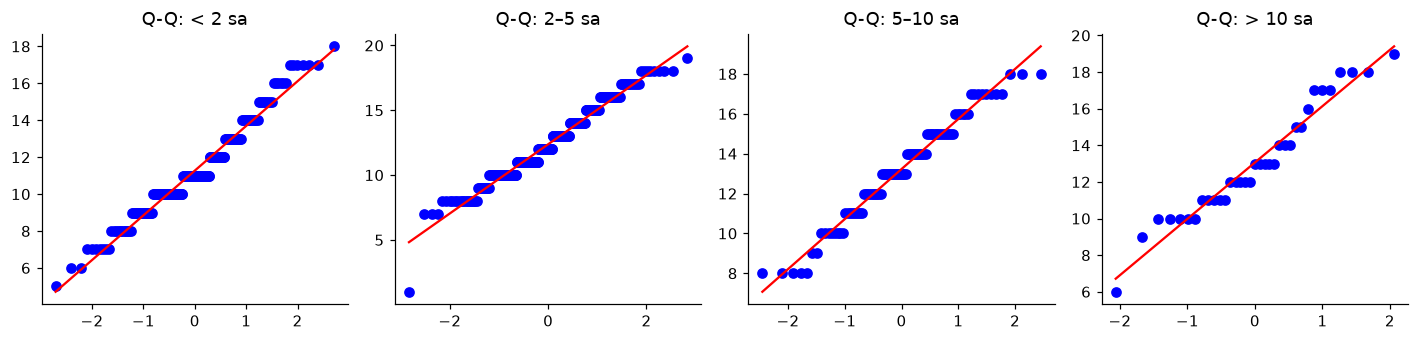

In [7]:
fig, eksenler = plt.subplots(1, 4, figsize=(13, 3.2))
for eksen, (ad, v) in zip(eksenler, g3.items()):
    stats.probplot(v, dist="norm", plot=eksen)
    eksen.set_title(f"Q-Q: {ad}")
    eksen.set_xlabel("")
    eksen.set_ylabel("")
plt.tight_layout()
plt.show()

Notlar 0–20 arası **tam sayılardır** ve üst uçta tavan etkisi vardır. Bu yüzden Q-Q grafiklerinde basamaklı görünüm oluşur ve Shapiro-Wilk testi, büyük gruplarda küçük sapmaları bile yakalar. Normallik sağlanmadığı için modül **Kruskal-Wallis** testini seçer. Bu seçimin doğru olup olmadığı `03_guc_simulasyonu.ipynb` dosyasında simülasyonla sınanır.

In [8]:
print(s_g3.rapor())
print(f"\nPost-hoc: {s_g3.posthoc_adi}")
s_g3.posthoc

Kruskal-Wallis: H(3) = 45.58, p < .001, ε² = 0.072 (küçük etki)

Post-hoc: Dunn + Holm


,Grup 1,Grup 2,Medyan farkı,z,p (düzeltilmiş),Anlamlı mı?
0,< 2 sa,2–5 sa,-1.0,-4.674,1.474e-05,Evet
1,< 2 sa,5–10 sa,-2.0,-6.151,4.611e-09,Evet
2,< 2 sa,> 10 sa,-2.0,-3.437,2.356e-03,Evet
3,2–5 sa,5–10 sa,-1.0,-2.856,1.286e-02,Evet
4,2–5 sa,> 10 sa,-1.0,-1.142,5.072e-01,Hayır
5,5–10 sa,> 10 sa,0.0,0.659,5.100e-01,Hayır


In [9]:
print(f"En yüksek final notu: {s_g3.en_iyi}")
print(f"Diğer tüm gruplardan anlamlı olarak yüksek mi? {ist.evet_hayir(s_g3.en_iyi_kesin)}")

En yüksek final notu: 5–10 sa
Diğer tüm gruplardan anlamlı olarak yüksek mi? Hayır


## 4. Soru 3: Dönem içi gelişim (G3 − G1) gruplara göre farklı mı?

Final notundaki farklar, gruplar arasında **başlangıçta** var olan farklardan kaynaklanıyor olabilir. Bunu ayırt etmek için önce 1. dönem notları (G1), sonra gelişim puanları (G3 − G1) karşılaştırılır.

In [10]:
s_g1 = ist.grup_karsilastir(gruplar(por_g, "G1"))
print("1. dönem notu (G1)  |", s_g1.rapor())

por_g["Gelisim"] = por_g.G3 - por_g.G1
s_gel = ist.grup_karsilastir(gruplar(por_g, "Gelisim"))
print("Gelişim (G3 − G1)   |", s_gel.rapor())
s_gel.posthoc

1. dönem notu (G1)  | Kruskal-Wallis: H(3) = 43.58, p < .001, ε² = 0.069 (küçük etki)
Gelişim (G3 − G1)   | Kruskal-Wallis: H(3) = 5.62, p = .132, ε² = 0.009 (önemsiz etki)


,Grup 1,Grup 2,Medyan farkı,z,p (düzeltilmiş),Anlamlı mı?
0,< 2 sa,2–5 sa,0.0,-0.931,0.831,Hayır
1,< 2 sa,5–10 sa,0.0,-1.087,0.831,Hayır
2,< 2 sa,> 10 sa,1.0,1.595,0.443,Hayır
3,2–5 sa,5–10 sa,0.0,-0.423,0.831,Hayır
4,2–5 sa,> 10 sa,1.0,2.106,0.185,Hayır
5,5–10 sa,> 10 sa,1.0,2.160,0.185,Hayır


## 5. Soru 4: En iyi grupta G1 ile G3 arasında fark var mı?

En yüksek medyan/ortalama sıraya sahip grup seçilir. Aynı öğrencilerin iki notu karşılaştırıldığı için bağımlı test kullanılır: farklar normal dağılırsa bağımlı t-testi, dağılmazsa Wilcoxon işaretli sıralar testi.

In [11]:
en_iyi_kod = {v: k for k, v in ETIKET.items()}[s_g3.en_iyi]
en_iyi = por_g[por_g.studytime == en_iyi_kod]
s_es = ist.eslesik_karsilastir(en_iyi.G1, en_iyi.G3)

print(f"Grup: {s_g3.en_iyi} (n = {len(en_iyi)})")
print(f"Farkların normalliği: Shapiro-Wilk {ist.p_yaz(s_es.fark_normal_p)}")
print(s_es.rapor())
print(f"\nG1 ortalaması: {en_iyi.G1.mean():.2f} | G3 ortalaması: {en_iyi.G3.mean():.2f}")

Grup: 5–10 sa (n = 97)
Farkların normalliği: Shapiro-Wilk p < .001
Wilcoxon işaretli sıralar: W = 348.0, p < .001, r (sıra-çift serisel) = 0.69 (büyük etki), medyan fark = +1.00, ortalama fark = +0.80 [%95 bootstrap GA 0.55, 1.07]

G1 ortalaması: 12.42 | G3 ortalaması: 13.23


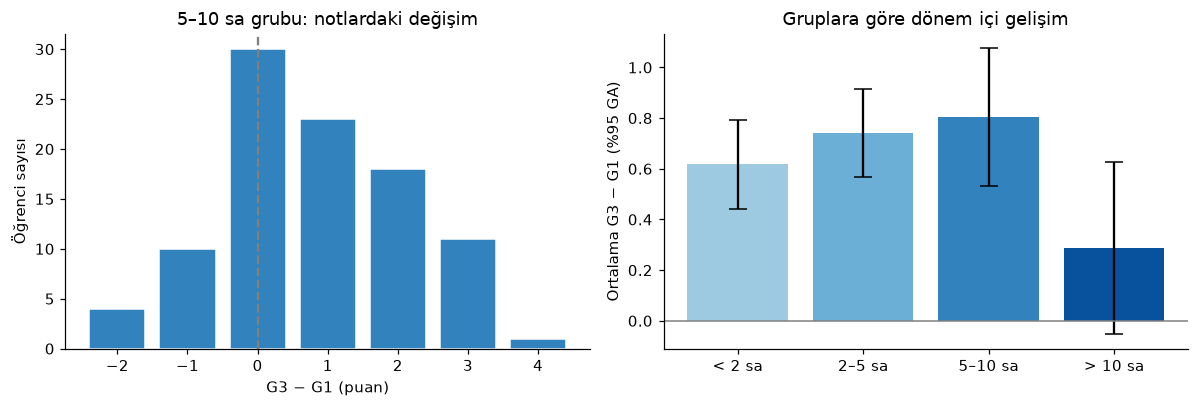

In [12]:
fig, eksenler = plt.subplots(1, 2, figsize=(11, 3.8))
sayim = (en_iyi.G3 - en_iyi.G1).value_counts().sort_index()
eksenler[0].bar(sayim.index, sayim.values, color=RENK[en_iyi_kod], edgecolor="white")
eksenler[0].axvline(0, color="gray", ls="--")
eksenler[0].set_xlabel("G3 − G1 (puan)")
eksenler[0].set_ylabel("Öğrenci sayısı")
eksenler[0].set_title(f"{s_g3.en_iyi} grubu: notlardaki değişim")

gelisim = por_g.groupby("studytime").Gelisim.agg(["mean", "sem", "size"])
hata = gelisim["sem"] * stats.t.ppf(0.975, gelisim["size"] - 1)
eksenler[1].bar(range(4), gelisim["mean"], yerr=hata, capsize=6,
                color=[RENK[k] for k in gelisim.index])
eksenler[1].axhline(0, color="gray", lw=1)
eksenler[1].set_xticks(range(4), [ETIKET[k] for k in gelisim.index])
eksenler[1].set_ylabel("Ortalama G3 − G1 (%95 GA)")
eksenler[1].set_title("Gruplara göre dönem içi gelişim")
plt.tight_layout()
plt.savefig(SEKIL / "portekizce_gelisim.png", bbox_inches="tight")
plt.show()

## 6. Soru 5: Replikasyon ve duyarlılık analizi

Aynı analiz iki ders ve iki veri seçimi (G3 > 0 / tüm öğrenciler) için tekrarlanır. Sonuç seçimlere göre değişiyorsa, bu durum raporda açıkça belirtilmelidir.

In [13]:
satirlar = []
for ders, veri in [("Portekizce", por), ("Matematik", mat)]:
    for secim, alt in [("G3 > 0", veri[veri.G3 > 0]), ("Tüm öğrenciler", veri)]:
        s = ist.grup_karsilastir(gruplar(alt, "G3"))
        satirlar.append({"Ders": ders, "Veri": secim, "n": len(alt), "Test": s.test_adi,
                         "İstatistik": round(s.istatistik, 2), "p": s.p, s.etki_adi: s.etki,
                         "Anlamlı?": ist.evet_hayir(s.p < ALPHA), "En yüksek": s.en_iyi,
                         "Kesin üstün?": ist.evet_hayir(s.en_iyi_kesin)})
replikasyon = pd.DataFrame(satirlar)
replikasyon

,Ders,Veri,n,Test,İstatistik,p,ε²,Anlamlı?,En yüksek,Kesin üstün?
0,Portekizce,G3 > 0,634,Kruskal-Wallis,45.58,6.981e-10,0.072,Evet,5–10 sa,Hayır
1,Portekizce,Tüm öğrenciler,649,Kruskal-Wallis,50.32,6.842e-11,0.078,Evet,5–10 sa,Hayır
2,Matematik,G3 > 0,357,Kruskal-Wallis,11.18,1.078e-02,0.031,Evet,> 10 sa,Hayır
3,Matematik,Tüm öğrenciler,395,Kruskal-Wallis,7.58,5.557e-02,0.019,Hayır,5–10 sa,Hayır


In [14]:
s_mat = ist.grup_karsilastir(gruplar(mat_g, "G3"))
print("Matematik (G3 > 0) |", s_mat.rapor())
s_mat.posthoc

Matematik (G3 > 0) | Kruskal-Wallis: H(3) = 11.18, p = .011, ε² = 0.031 (küçük etki)


,Grup 1,Grup 2,Medyan farkı,z,p (düzeltilmiş),Anlamlı mı?
0,< 2 sa,2–5 sa,0.0,0.842,0.799,Hayır
1,< 2 sa,5–10 sa,-1.0,-1.995,0.203,Hayır
2,< 2 sa,> 10 sa,-1.5,-1.469,0.425,Hayır
3,2–5 sa,5–10 sa,-1.0,-2.940,0.020,Evet
4,2–5 sa,> 10 sa,-1.5,-2.047,0.203,Hayır
5,5–10 sa,> 10 sa,-0.5,-0.017,0.987,Hayır


### Welch ANOVA ile sağlamlık kontrolü

`03_guc_simulasyonu.ipynb` dosyasındaki simülasyon şunu gösterir: Bu verinin koşullarında (dengesiz gruplar, biraz farklı varyanslar, çarpık ve basamaklı not dağılımı) Kruskal-Wallis testinin "ortalamalar eşit" hipotezi için I. tip hata oranı yaklaşık %10'dur. Welch ANOVA ise %5 düzeyini korur ve gücü benzerdir. Bu nedenle sonuçlar Welch ANOVA + Games-Howell ile de kontrol edilir.

In [15]:
for ders, veri in [("Portekizce", por_g), ("Matematik", mat_g)]:
    s = ist.grup_karsilastir(gruplar(veri, "G3"), zorla="welch")
    print(f"{ders:10} | {s.rapor()}")
    anlamli = s.posthoc[s.posthoc["p (düzeltilmiş)"] < ALPHA]
    print("           Anlamlı farklar (Games-Howell):",
          ", ".join(f"{r['Grup 1']} vs {r['Grup 2']} ({r['Ort. farkı']:+.2f})" for _, r in anlamli.iterrows()))

Portekizce | Welch ANOVA: F(3, 133.4) = 16.42, p < .001, ω² = 0.068 (orta etki)
           Anlamlı farklar (Games-Howell): < 2 sa vs 2–5 sa (-1.11), < 2 sa vs 5–10 sa (-1.96), < 2 sa vs > 10 sa (-1.79), 2–5 sa vs 5–10 sa (-0.85)


Matematik  | Welch ANOVA: F(3, 85.7) = 4.46, p = .006, ω² = 0.028 (küçük etki)
           Anlamlı farklar (Games-Howell): 2–5 sa vs 5–10 sa (-1.49)


## 7. Sonuç ve yorum

| Soru | Bulgu |
|---|---|
| 1. G3 gruplara göre farklı mı? | **Evet.** Portekizce: Kruskal-Wallis H(3) = 45.58, p < .001, ε² = 0.07 (küçük etki). Welch ANOVA aynı sonucu verir. |
| 2. En iyi grup? | **5–10 saat** grubu, ancak > 10 saat grubundan anlamlı olarak farklı değildir (p = .51). Kesin bir "en iyi" grup yoktur. Haftada 5 saati aşan çalışmanın ek getirisi görülmemektedir. |
| 3. Gelişim (G3 − G1) farklı mı? | **Hayır** (H(3) = 5.62, p = .132). Gruplar arasındaki fark 1. dönemde **zaten vardır** (G1 için H(3) = 43.58, p < .001). Daha çok çalışan öğrenciler dönem boyunca daha fazla ilerlememektedir; baştan beri daha başarılıdırlar. |
| 4. En iyi grupta G1 ile G3 farkı | **Var ama küçük:** Wilcoxon p < .001, ortalama artış +0.80 puan (%95 GA 0.55–1.07, 20'lik ölçekte). Tüm gruplarda benzer artış vardır; bu artış yönteme özgü değildir. |
| 5. Replikasyon (Matematik) | **Zayıf.** Etki daha küçüktür (ε² = 0.03) ve sonuç veri seçimine bağlıdır: G3 = 0 olan öğrenciler dahil edilince p = .056 olur ve sonuç anlamsızlaşır. Post-hoc testte yalnızca 2–5 sa ile 5–10 sa arasındaki fark anlamlıdır. |

**Genel değerlendirme**

- Çalışma süresi ile final notu arasında **gerçek ama küçük** bir ilişki vardır. Bu ilişki Portekizce dersinde güçlü, Matematik dersinde zayıf ve kırılgandır.
- G3'teki farkın neredeyse tamamı 1. dönemde zaten mevcuttur. Bu nedenle "daha çok çalışmak notu yükseltir" gibi **nedensel bir sonuç çıkarılamaz**. Çalışma süresi, motivasyon veya önceki başarı gibi başka bir etkenin göstergesi olabilir.
- Sentetik veride (01) d_z = 3.5 gibi gerçekçi olmayan etkiler bulundu. Gerçek veride etkiler küçüktür. Bu, eğitim araştırmalarında beklenen bir durumdur.

**Sınırlılıklar:** Gözlemsel veri; çalışma süresi öğrenci beyanıdır; > 10 saat grubu küçüktür (n = 35); veri iki okuldan gelmektedir ve genellenebilirliği sınırlıdır; G3 = 0 değerlerinin sınava girmeme olarak yorumlanması bir varsayımdır.
